# Where cells sit in the cycle

A drug that stops the cell cycle leaves its mark in the DNA content of the cells it stopped. This tutorial places
single cells on the cycle from their DNA stain with {func}`~mantispy.tl.fit_cell_cycle` and
{func}`~mantispy.tl.project_cell_cycle`, and checks the result against drugs whose effect on the cycle is known.

The data are MCF-7 nuclei from BBBC021 ({func}`~mantispy.ds.bbbc021_cells`): fifteen compounds in three replicate
wells each, and one DMSO well from every plate they sit on. Each mechanism of action predicts a place in the cycle,
so we state the predictions before looking:

| Mechanism | Prediction |
| --- | --- |
| Microtubule destabilizers and stabilizers, Eg5 inhibitors | stop cells in mitosis, so more cells at 4N and more flagged as mitotic |
| Aurora kinase inhibitors | let cells skip division, so cells above 4N |
| DNA replication inhibitors | stall replication, so more cells in S |
| DNA damage | stop cells before mitosis, so more cells in G2 |
| Cholesterol-lowering (statins) | no cell-cycle target, so the same distribution as DMSO |

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import mantispy as mt

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110

cells = mt.ds.bbbc021_cells()
cells.obs.groupby("Metadata_MOA", observed=True)["Metadata_Compound"].agg(["nunique", "size"]).rename(
    columns={"nunique": "compounds", "size": "nuclei"}
)

,compounds,nuclei
Metadata_MOA,,
Aurora kinase inhibitors,2,3081
Cholesterol-lowering,2,1100
DMSO,1,22509
DNA damage,2,3946
DNA replication,3,3719
Eg5 inhibitors,2,1934
Microtubule destabilizers,2,1537
Microtubule stabilizers,2,1672


## DNA content

{func}`~mantispy.tl.dna_content` turns the integrated DAPI intensity into doublings of the G1 peak, so a 2N nucleus
sits near 0 and a 4N nucleus near 1. The G1 peak is normally measured in each well, since staining differs between
wells. Here that would fail. A well of arrested cells has no G1 peak of its own, and its 4N peak would be taken for
one. So the peak is measured on the DMSO cells of each plate (``reference="negcon"``) and applied to every well on
that plate.

In [2]:
mt.tl.dna_content(
    cells, dna_feature="Nuclei_Intensity_IntegratedIntensity_DAPI", by="Metadata_Plate", reference="negcon"
)

## The DMSO clock

{func}`~mantispy.tl.fit_cell_cycle` fits the clock on the DMSO cells. It first checks that they cycle: a 2N peak, a
separate 4N peak and S cells between them. It then orders the cells G1, S and G2M by DNA content and turns each
cell's cumulative share into a position in the cycle, corrected for the age distribution of a growing population.
DNA content cannot tell a cell in mitosis from one in G2, since both hold 4N, so the two share one phase.

In [3]:
mt.tl.fit_cell_cycle(cells, reference="negcon")
model = cells.uns["mantispy"]["cell_cycle"]
print("DMSO shares of G1, S and G2M:", np.round(model["fractions"], 3))
pd.Series(model["gate"]).round(3)

DMSO shares of G1, S and G2M: [0.567 0.247 0.186]


peak_4n          0.88
peak_ratio      0.504
valley_ratio    0.595
s_floor         0.595
s_share          0.23
passed              1
dtype: object

{func}`~mantispy.tl.project_cell_cycle` places every nucleus on the DMSO clock. Each one gets a phase, a
position from 0 (the start of G1) to 1 (division), and an interval around that position. It also checks every well
against the DMSO cells, and warns about a well whose 2N and 4N peaks both sit off the DMSO peaks by the same amount:
such a well reads its DNA stain differently, and every position in it carries that shift.

project_cell_cycle: 12 ('Metadata_Plate', 'Metadata_Well') group(s) have both their 2N and 4N peaks off the reference's, so their DNA stain reads differently and their positions carry the shift given, in doublings: {('Week10_40111', 'C06'): -0.13, ('Week1_22123', 'E04'): -0.22, ('Week1_22161', 'E04'): -0.21, ('Week3_25461', 'B07'): -0.14, ('Week4_27801', 'C06'): 0.18}


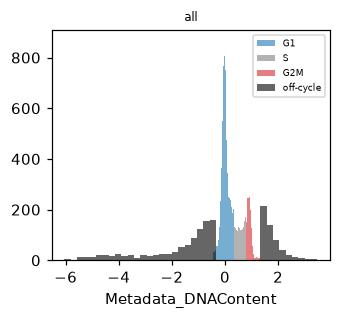

In [4]:
mt.tl.project_cell_cycle(cells)
dmso = cells[cells.obs["Metadata_MOA"] == "DMSO"]
mt.pl.cell_cycle(dmso, dna_feature="Metadata_DNAContent", key="cell_cycle_phase", by=None)

An S nucleus is placed tightly, because its DNA content says how far replication has gone. A G1 or G2M
nucleus gets its whole plateau as the interval, because DNA content does not order cells within it. A nucleus
outside the DMSO DNA range, below 2N or above 4N, is off the cycle.

The well check needs both peaks. A well arrested at 4N has no 2N peak, and a single peak cannot say whether the
cells or the stain moved, so such a well goes unchecked rather than corrected. The table counts, per mechanism, the
wells the check could judge and those it found shifted.

In [5]:
obs = cells.obs
well = obs.groupby(["Metadata_MOA", "Metadata_Plate", "Metadata_Well"], observed=True)["cell_cycle_well_shift"].first()
well = well.reset_index()
well.groupby("Metadata_MOA").agg(
    wells=("cell_cycle_well_shift", "size"),
    checked=("cell_cycle_well_shift", lambda s: s.notna().sum()),
    shifted=("cell_cycle_well_shift", lambda s: (s.abs() > model["sd"]).sum()),
    median_shift=("cell_cycle_well_shift", "median"),
).round(2)

,wells,checked,shifted,median_shift
Metadata_MOA,,,,
Aurora kinase inhibitors,6,5,2,0.03
Cholesterol-lowering,6,5,3,-0.11
DMSO,27,26,2,-0.04
DNA damage,6,4,1,0.02
DNA replication,9,1,0,-0.09
Eg5 inhibitors,6,1,1,-0.13
Microtubule destabilizers,6,3,3,-0.21
Microtubule stabilizers,6,1,0,-0.10


The check judged 46 of the 72 wells, and found 2 of the 26 DMSO wells it judged shifted. All three
microtubule destabilizer wells it could judge are shifted, by -0.14 to -0.22 doublings. Most wells of the
microtubule stabilizers, the Eg5 inhibitors and the DNA replication drugs have only one of the two peaks, so they
go unchecked.

## Phases by mechanism

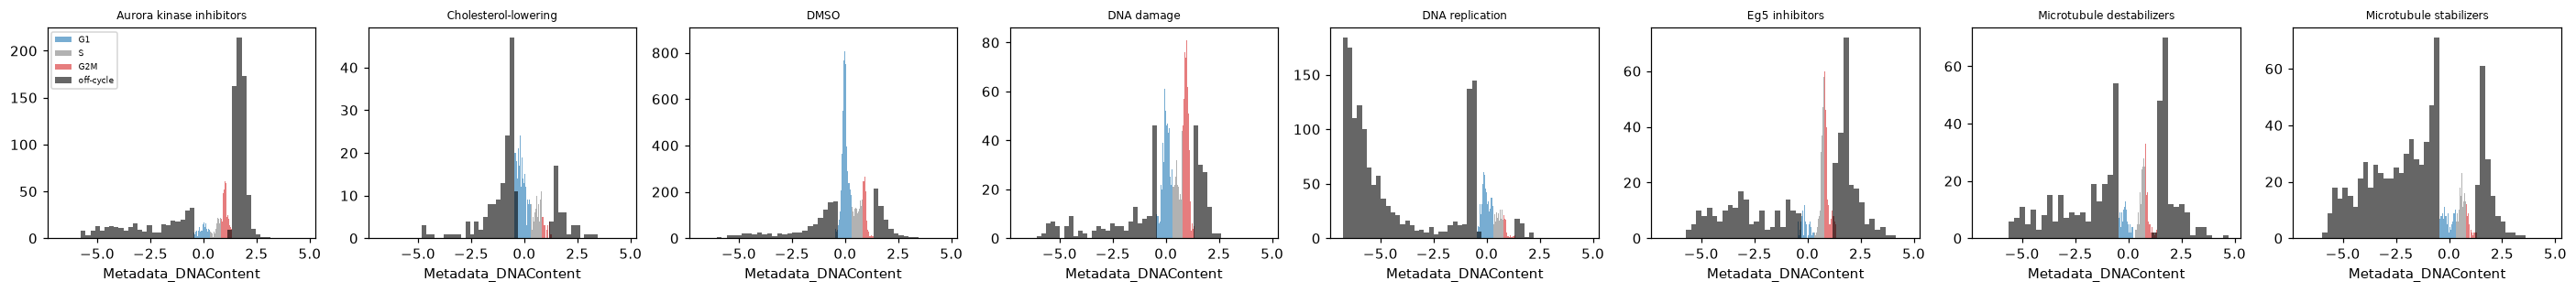

In [6]:
mt.pl.cell_cycle(cells, dna_feature="Metadata_DNAContent", key="cell_cycle_phase", by="Metadata_MOA")

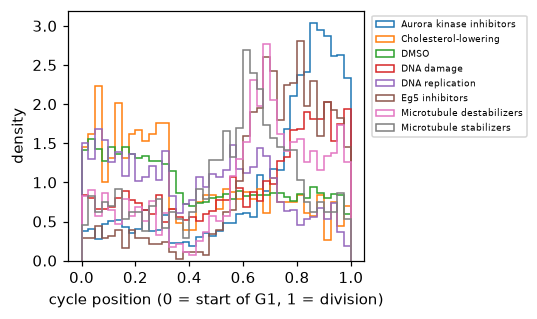

In [7]:
mt.pl.cell_cycle(cells, position="cell_cycle", by="Metadata_MOA")

The occupancy plot draws one position per nucleus from its interval, so a mechanism that piles cells up at
one place in the cycle stands out against DMSO. The table puts numbers on both plots: each mechanism's share of
nuclei per phase minus the DMSO share, with the off-cycle nuclei split into those below 2N and those above 4N.

In [8]:
low, high = model["off_cycle"]
phase = obs["cell_cycle_phase"].astype(str).where(obs["cell_cycle_phase"] != "off-cycle", "")
phase[obs["Metadata_DNAContent"] < low] = "below 2N"
phase[obs["Metadata_DNAContent"] > high] = "above 4N"
columns = ["G1", "S", "G2M", "below 2N", "above 4N"]
share = pd.crosstab(obs["Metadata_MOA"], phase, normalize="index")[columns]
change = share - share.loc["DMSO"]
change.drop(index="DMSO").round(3)

cell_cycle_phase,G1,S,G2M,below 2N,above 4N
Metadata_MOA,,,,,
Aurora kinase inhibitors,-0.404,-0.077,0.244,0.060,0.177
Cholesterol-lowering,-0.027,-0.010,-0.067,0.089,0.015
DNA damage,-0.237,0.005,0.226,-0.001,0.007
DNA replication,-0.189,-0.007,-0.124,0.334,-0.014
Eg5 inhibitors,-0.445,0.163,0.142,0.056,0.084
Microtubule destabilizers,-0.358,0.144,0.002,0.121,0.090
Microtubule stabilizers,-0.360,0.090,-0.086,0.294,0.062


## Checking the predictions

Each prediction becomes a rule on the table above, with a change of 0.05 (five percentage points of nuclei) as the
smallest one that counts. The mitosis half of the first three predictions cannot be checked: the clock has no
mitosis call, so they are checked on G2M alone.

In [9]:
rules = {
    "Microtubule destabilizers": ("G2M up", lambda c: c["G2M"] > 0.05),
    "Microtubule stabilizers": ("G2M up", lambda c: c["G2M"] > 0.05),
    "Eg5 inhibitors": ("G2M up", lambda c: c["G2M"] > 0.05),
    "Aurora kinase inhibitors": ("above 4N up", lambda c: c["above 4N"] > 0.05),
    "DNA replication": ("S up", lambda c: c["S"] > 0.05),
    "DNA damage": ("G2M up", lambda c: c["G2M"] > 0.05),
    "Cholesterol-lowering": ("no phase moves", lambda c: (c[["G1", "S", "G2M"]].abs() <= 0.05).all()),
}
pd.DataFrame(
    [(moa, rule, bool(test(change.loc[moa]))) for moa, (rule, test) in rules.items()],
    columns=["mechanism", "prediction", "holds"],
).set_index("mechanism")

,prediction,holds
mechanism,,
Microtubule destabilizers,G2M up,False
Microtubule stabilizers,G2M up,False
Eg5 inhibitors,G2M up,True
Aurora kinase inhibitors,above 4N up,True
DNA replication,S up,False
DNA damage,G2M up,True
Cholesterol-lowering,no phase moves,False


Three predictions hold. The Aurora kinase inhibitors put cells above 4N, and the DNA damage drugs and
the Eg5 inhibitors put cells in G2M. The microtubule drugs, the DNA replication drugs and the statins fail. A
mechanism mixes compounds, so the same table per compound shows which of them carry each result.

In [10]:
by_compound = pd.crosstab(obs["Metadata_Perturbation"], phase, normalize="index")[columns]
moa_of = obs.groupby("Metadata_Perturbation", observed=True)["Metadata_MOA"].first()
(by_compound - by_compound.loc["DMSO@0.0"]).drop(index="DMSO@0.0").assign(mechanism=moa_of).sort_values(
    "mechanism"
).round(2)

cell_cycle_phase,G1,S,G2M,below 2N,above 4N,mechanism
Metadata_Perturbation,,,,,,
AZ258@1.0,-0.42,0.02,0.15,0.03,0.22,Aurora kinase inhibitors
AZ841@1.0,-0.39,-0.15,0.31,0.08,0.15,Aurora kinase inhibitors
mevinolin/lovastatin@15.0,-0.02,-0.04,-0.03,0.06,0.02,Cholesterol-lowering
simvastatin@20.0,-0.04,0.01,-0.10,0.11,0.01,Cholesterol-lowering
etoposide@3.0,-0.25,-0.09,0.33,-0.01,0.02,DNA damage
mitomycin C@1.0,-0.22,0.10,0.12,0.01,-0.01,DNA damage
camptothecin@0.03,-0.30,0.33,-0.02,-0.01,0.00,DNA replication
floxuridine@30.0,-0.28,-0.12,-0.15,0.56,-0.02,DNA replication
methotrexate@10.0,0.02,-0.08,-0.15,0.23,-0.02,DNA replication


## Where the predictions fail

Every microtubule drug lowered G1 by 0.33 to 0.38 and raised S more than G2M. The well check shows why
for the wells it could judge:

In [11]:
checked = well[well["cell_cycle_well_shift"].notna()]
checked[checked["Metadata_MOA"].isin(["Microtubule destabilizers", "Microtubule stabilizers", "Eg5 inhibitors"])].round(
    2
)

,Metadata_MOA,Metadata_Plate,Metadata_Well,cell_cycle_well_shift
54,Eg5 inhibitors,Week10_40111,C06,-0.13
60,Microtubule destabilizers,Week1_22123,E04,-0.22
62,Microtubule destabilizers,Week1_22161,E04,-0.21
65,Microtubule destabilizers,Week3_25461,B07,-0.14
70,Microtubule stabilizers,Week7_34381,C05,-0.10


Each judged well of these drugs reads its stain low, by 0.10 to 0.22 doublings, so its 4N nuclei
land near 0.7 instead of at the DMSO peak of 0.88, where the DMSO clock places S.

A loss that hits only mitotic cells, such as condensed chromosomes measured short, would look the same in a well
full of them. It does not happen in the DMSO wells. Their nuclei with the most uneven DAPI, as condensed
chromosomes give, do not read low:

In [12]:
X = cells[:, ["Nuclei_Intensity_StdIntensity_DAPI", "Nuclei_Intensity_MeanIntensity_DAPI"]].to_df()
variation = X.iloc[:, 0] / X.iloc[:, 1]
upper = (obs["Metadata_MOA"] == "DMSO") & (obs["Metadata_DNAContent"] > 0.4)
condensed = upper & (variation > variation[upper].quantile(0.98))
pd.DataFrame(
    {
        "nuclei": [condensed.sum(), (upper & ~condensed).sum()],
        "median DNA content": [
            obs.loc[condensed, "Metadata_DNAContent"].median(),
            obs.loc[upper & ~condensed, "Metadata_DNAContent"].median(),
        ],
    },
    index=["most uneven 2% of DAPI", "the rest"],
).round(2)

,nuclei,median DNA content
most uneven 2% of DAPI,177,1.01
the rest,8662,0.80


They read at 1.01, against 0.80 for the rest of the upper half of the cycle. In the wells that can be
judged, the 2N cells read low as well as the 4N cells, so the cause lies in the well, not in mitosis. These data do
not say what it is. Most stabilizer and Eg5 wells have no 2N peak and cannot be judged, and their low reading may
have either cause.

The statins fail on G2M, which falls by 0.07. Three of their five judged wells are shifted, two of them with fewer
than 90 nuclei.

The DNA replication drugs split. Camptothecin moves cells into S. Floxuridine and methotrexate move many cells below
2N, and a table by well shows where these come from.

In [13]:
area = cells[:, "Nuclei_AreaShape_Area"].to_df().iloc[:, 0]
wells = obs.assign(area=area, below_2N=obs["Metadata_DNAContent"] < low)
wells = wells[wells["Metadata_MOA"].isin(["DNA replication", "Cholesterol-lowering"])]
wells.groupby(["Metadata_Perturbation", "Metadata_Plate"], observed=True).agg(
    nuclei=("area", "size"),
    median_area=("area", "median"),
    median_dna=("Metadata_DNAContent", "median"),
    below_2N=("below_2N", "mean"),
    well_shift=("cell_cycle_well_shift", "first"),
).round(2)

nuclei  median_area  median_dna  \
Metadata_Perturbation     Metadata_Plate                                    
camptothecin@0.03         Week8_38203        255       1168.0        0.60   
                          Week8_38221        327       1215.0        0.61   
                          Week8_38241        234       1222.5        0.76   
floxuridine@30.0          Week9_39282       1210         55.0       -5.84   
                          Week9_39283        366       1138.0        0.20   
                          Week9_39301        192       1142.5        0.18   
methotrexate@10.0         Week2_24121        324        975.5       -0.07   
                          Week2_24141        459       1001.0       -0.63   
                          Week2_24161        352        982.0       -0.07   
mevinolin/lovastatin@15.0 Week9_39206         79        602.0       -0.05   
                          Week9_39221        311        643.0        0.07   
                          Week9_39222        131        583.0        0.06   
simvastatin@20.0          Week9_39282         85        694.0        0.46   
                          Week9_39283        419        605.0       -0.22   
                          Week9_39301         75        577.0       -0.19   

                                          below_2N  well_shift  
Metadata_Perturbation     Metadata_Plate                        
camptothecin@0.03         Week8_38203         0.04         NaN  
                          Week8_38221         0.03         NaN  
                          Week8_38241         0.02       -0.09  
floxuridine@30.0          Week9_39282         0.87         NaN  
                          Week9_39283         0.03         NaN  
                          Week9_39301         0.03         NaN  
methotrexate@10.0         Week2_24121         0.05         NaN  
                          Week2_24141         0.59         NaN  
                          Week2_24161         0.04         NaN  
mevinolin/lovastatin@15.0 Week9_39206         0.18       -0.37  
                          Week9_39221         0.10       -0.11  
                          Week9_39222         0.06       -0.09  
simvastatin@20.0          Week9_39282         0.06        0.27  
                          Week9_39283         0.14       -0.33  
                          Week9_39301         0.35         NaN

In one floxuridine well, the 1,210 objects have a median area of 55 pixels, against more than 1,100 in
the other two wells. The segmentation picked up debris there, not nuclei. One methotrexate well has 59% of its
nuclei below 2N at normal size. The other wells of both drugs have a median DNA content close to 0, the G1 peak,
and the table per compound shows no gain in S for either drug. The well check judges none of these six wells, since
each lacks one of the two peaks. A table by mechanism hides problems like these, so check the wells before reading
it.